# 03 - More features for QUANT? (v2; small and medium datasets, all cores)

Before making TabPFN cheaper, we asked whether QUANT's accuracy can be raised by giving the classifiers more
features. Each v2 variant adds one kind of feature to QUANT's and filters it back on the training data (ANOVA
F-score), for all four classifiers (ExtraTrees = the original QUANT classifier, XGBoost, CatBoost and TabPFN on the
GPU). The answer is mostly no, so this chapter is kept short in the report; the lag-d differences are the one addition
that is cheap and kept for the later versions.

| Version | Features given to the classifiers |
|---|---|
| **v1** | QUANT only (the baseline) |
| **v2-lagd** | **all** QUANT features + the best lag-d features, as many as QUANT has |
| **v2-lagd-joint** | QUANT + lag-d, filtered together back to QUANT's count (the same number of features as v1) |
| **v2-multirocket** | all QUANT features + the best lag-d + the best MultiRocket features |
| **v2-rdst** | as v2-multirocket, with the best RDST shapelet features instead of MultiRocket |
| **v2-mrhydra** | QUANT + the best MR-Hydra (MultiRocket + Hydra) features |

lag-d differences: x(t) - x(t-d) for d = 2, 4, 8, 16, summarised with QUANT's own interval quantiles. Unfiltered
extended feature sets (QUANT + all MR-Hydra features, about 56,000 features) were too large for our hardware (a 6 GB
GPU and a laptop's memory), so the added sets are always filtered: each keeps only its best features, as many as QUANT
has, and a version gives the classifiers 1 to 3 times QUANT's features. For MultiRocket and RDST the test set gets
only the kept features ("predict with few": the same values as computing all of them, several times faster).

**Datasets** (`improvedQuant/dataSetLists/`):
- **small** (`smoke-small.txt`): Coffee, GunPoint, ItalyPowerDemand, ECG200, Beef (28 to 100 training cases);
- **medium** (`smoke-medium.txt`): ChlorineConcentration, UWaveGestureLibraryX, SharePriceIncrease,
  PhalangesOutlinesCorrect, AconityMINIPrinterLargeEq (467 to 2,403 training cases).

Resamples 0, 1, 2 (15 runs per version, classifier and list); all CPU cores, the GPU classifiers on the GPU, seed 0,
the same splits for every version. Files: `results/{version}_smoke-{small,medium}_allcores-gpu.csv`.

**How the files are produced:** see `experiments.md`, v1 and v2. XGBoost and CatBoost skip runs with more than
14,000 features (too large for the 6 GB GPU); no run here is above the limit.

Caveat: a smoke test (5 datasets x 3 resamples per list): a first signal, not a conclusion. The 3 resamples of one
dataset are not independent, so the 15 runs are not 15 independent comparisons.

## 1. Settings and data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import TwoSlopeNorm

# the shared names, colours, plot style and loading of all notebooks: notebooks/common.py
from common import (CLASSIFIERS, DIVERGING, GRID, LABELS, MUTED, RESULTS_DIR, TEXT, VERSION_COLORS, dataset_list,
                    load_runs, offsets, read_split, short, signed, style)

style()
GROUPS = ["small", "medium"]           # the two dataset lists; every section shows both
VERSIONS = ["v1", "v2-lagd", "v2-lagd-joint", "v2-multirocket", "v2-rdst", "v2-mrhydra"]
OTHERS = VERSIONS[1:]                  # the versions compared with v1
DATASETS_OF = {group: dataset_list(f"smoke-{group}") for group in GROUPS}

# one table with every run of the 12 files, each run marked with its dataset list and version
frames = []
for group in GROUPS:
    for version in VERSIONS:
        d = load_runs(RESULTS_DIR / f"{version}_smoke-{group}_allcores-gpu.csv")
        d["group"] = group
        d["version"] = version
        frames.append(d)
runs = pd.concat(frames, ignore_index=True)
runs = runs[runs["status"] == "ok"]                                   # the finished runs (in these files: all of them)
runs["n_kept_extra"] = runs["n_kept_extra"].fillna(runs["n_features_extra_kept"])   # v2-mrhydra's older name for it
RUNS = {group: runs[runs["group"] == group] for group in GROUPS}       # the runs of one dataset list

def group_title(fig, group, top=0.95):
    """Name the dataset list above a figure."""
    fig.suptitle(f"{group} datasets", x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, top))

## 2. The datasets

Training and test cases (the same for every resample), series length, number of classes, and the number of QUANT
features (it grows with the series length).

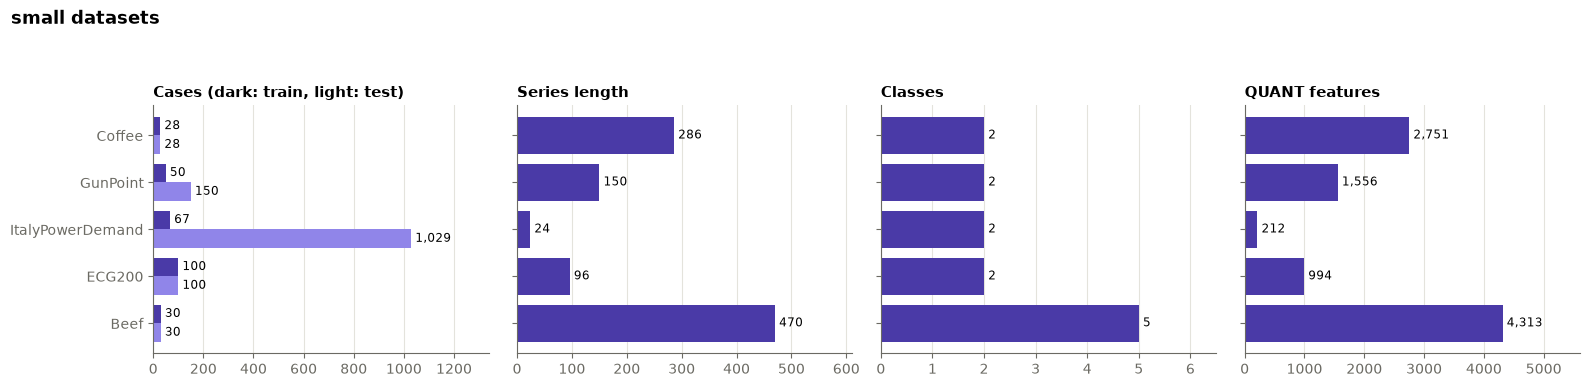

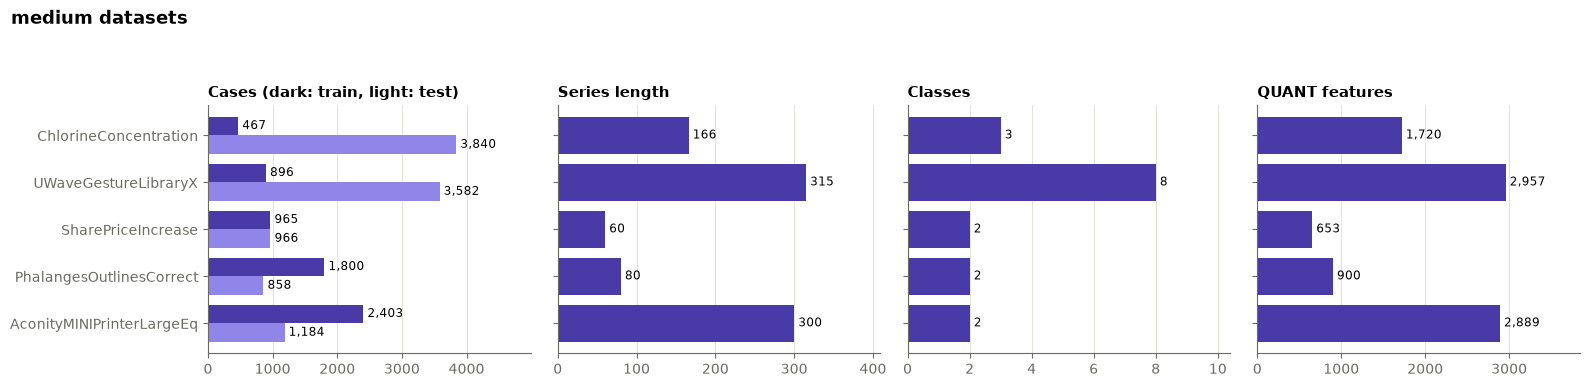

In [2]:
INFO = {}                              # per list: the dataset facts
panels = [(["train cases", "test cases"], "Cases (dark: train, light: test)"), (["length"], "Series length"),
          (["classes"], "Classes"), (["QUANT features"], "QUANT features")]
for group in GROUPS:
    group_runs, names = RUNS[group], DATASETS_OF[group]
    info = []
    for name in names:
        n_train, length, labels_train = read_split(name, "TRAIN")
        n_test, _, labels_test = read_split(name, "TEST")
        v1_rows = group_runs[(group_runs["version"] == "v1") & (group_runs["dataset"] == name)]
        info.append({"dataset": name, "train cases": n_train, "test cases": n_test, "length": length,
                     "classes": len(labels_train | labels_test), "QUANT features": v1_rows["n_features"].iloc[0]})
    INFO[group] = info_table = pd.DataFrame(info).set_index("dataset")

    fig, axes = plt.subplots(1, len(panels), figsize=(16, 3.9), sharey=True)
    y = np.arange(len(names))[::-1]                                    # the first dataset at the top
    for ax, (columns, title) in zip(axes, panels):
        height = 0.8 / len(columns)
        for k, (column, color) in enumerate(zip(columns, ["#4a3aa7", "#9085e9"])):
            shift = ((len(columns) - 1) / 2 - k) * height              # two columns: the first above the second
            bars = ax.barh(y + shift, info_table[column], height, color=color)
            ax.bar_label(bars, fmt="{:,.0f}", padding=3, fontsize=8.5)
        ax.set_xlim(0, info_table[columns].values.max() * 1.3)
        ax.set_title(title, loc="left")
        ax.grid(True, axis="x")
        ax.grid(False, axis="y")
    axes[0].set_yticks(y, info_table.index)
    group_title(fig, group, top=0.91)
    plt.show()

## 3. Features given to the classifiers

Mean over the datasets and resamples: how many features come from QUANT, from the lag-d differences and from the extra
feature set (MR-Hydra, MultiRocket or RDST). The same for every classifier, except TabPFN, which keeps its 500 best.

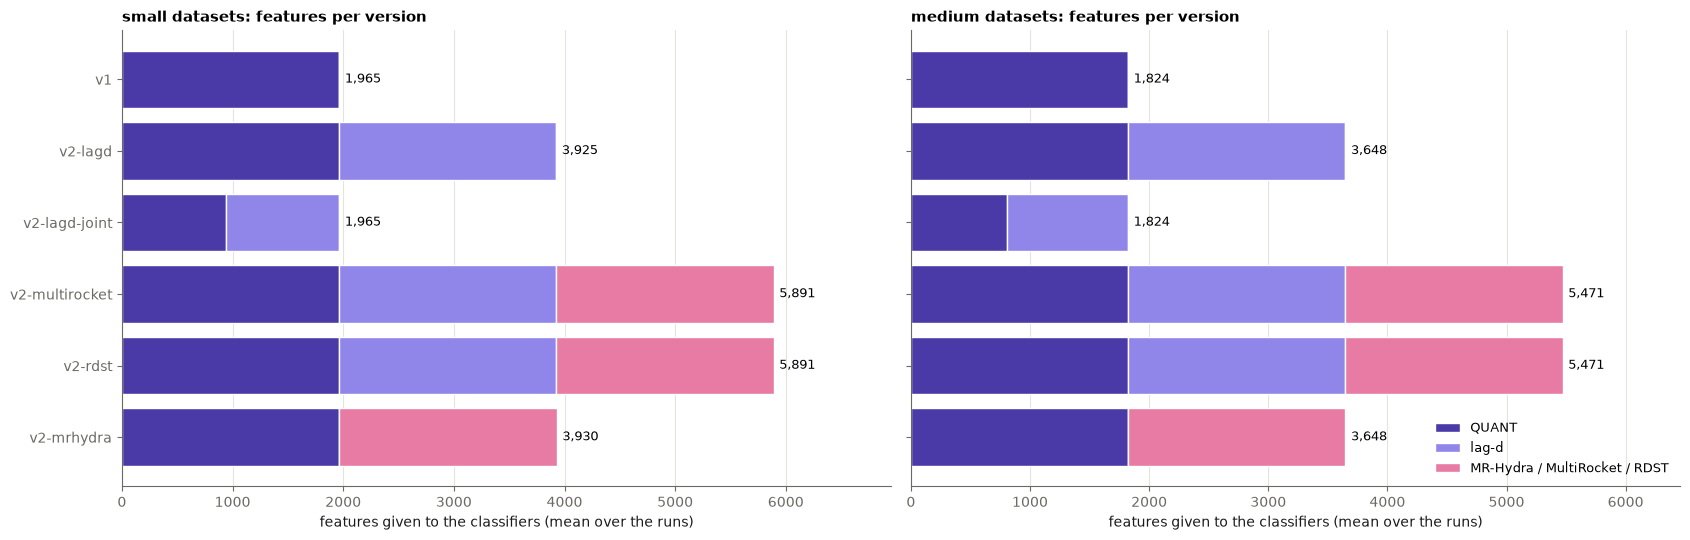

In [3]:
PART_COLORS = {"QUANT": "#4a3aa7", "lag-d": "#9085e9", "MR-Hydra / MultiRocket / RDST": "#e87ba4"}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), sharey=True)
for ax, group in zip(axes, GROUPS):
    et = RUNS[group][RUNS[group]["classifier"] == "extratrees"]      # the features are the same for every classifier
    parts = pd.DataFrame({
        "QUANT": et["n_kept_quant"].fillna(et["n_features_quant"]).fillna(et["n_features"]),   # lag-d versions, else v2-mrhydra, else v1
        "lag-d": et["n_kept_lag"].fillna(0),
        "MR-Hydra / MultiRocket / RDST": et["n_kept_extra"].fillna(0),
    })
    features = parts.groupby(et["version"]).mean().reindex(VERSIONS)  # the mean over the datasets and resamples
    y = np.arange(len(VERSIONS))[::-1]
    left = np.zeros(len(VERSIONS))
    for part, color in PART_COLORS.items():
        bars = ax.barh(y, features[part], left=left, color=color, edgecolor="white", label=part)
        left += features[part].values
    ax.bar_label(bars, labels=[f"{total:,.0f}" for total in left], padding=4, fontsize=9)   # the total, after the last part
    ax.set_yticks(y, VERSIONS)
    ax.set_xlim(0, left.max() * 1.18)
    ax.set_xlabel("features given to the classifiers (mean over the runs)")
    ax.set_title(f"{group} datasets: features per version", loc="left")
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
axes[1].legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Every version, every classifier

One figure per dataset list; means over the 15 runs: one group of bars per classifier, one bar per version (left to right in the order of the
legend).

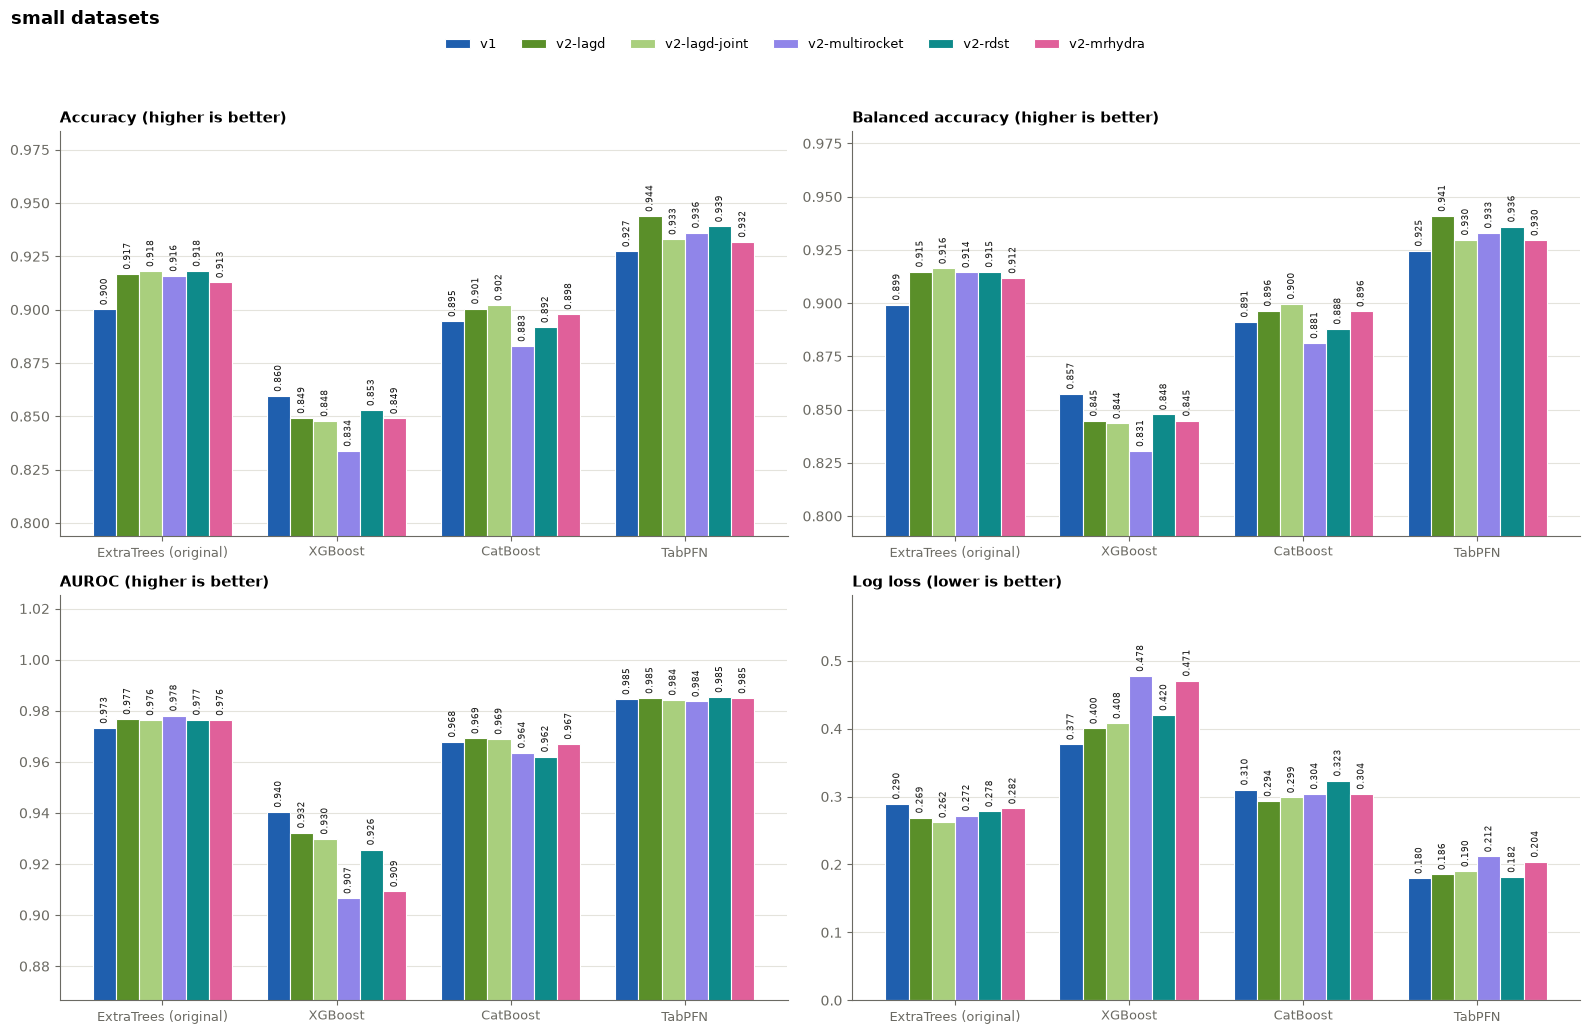

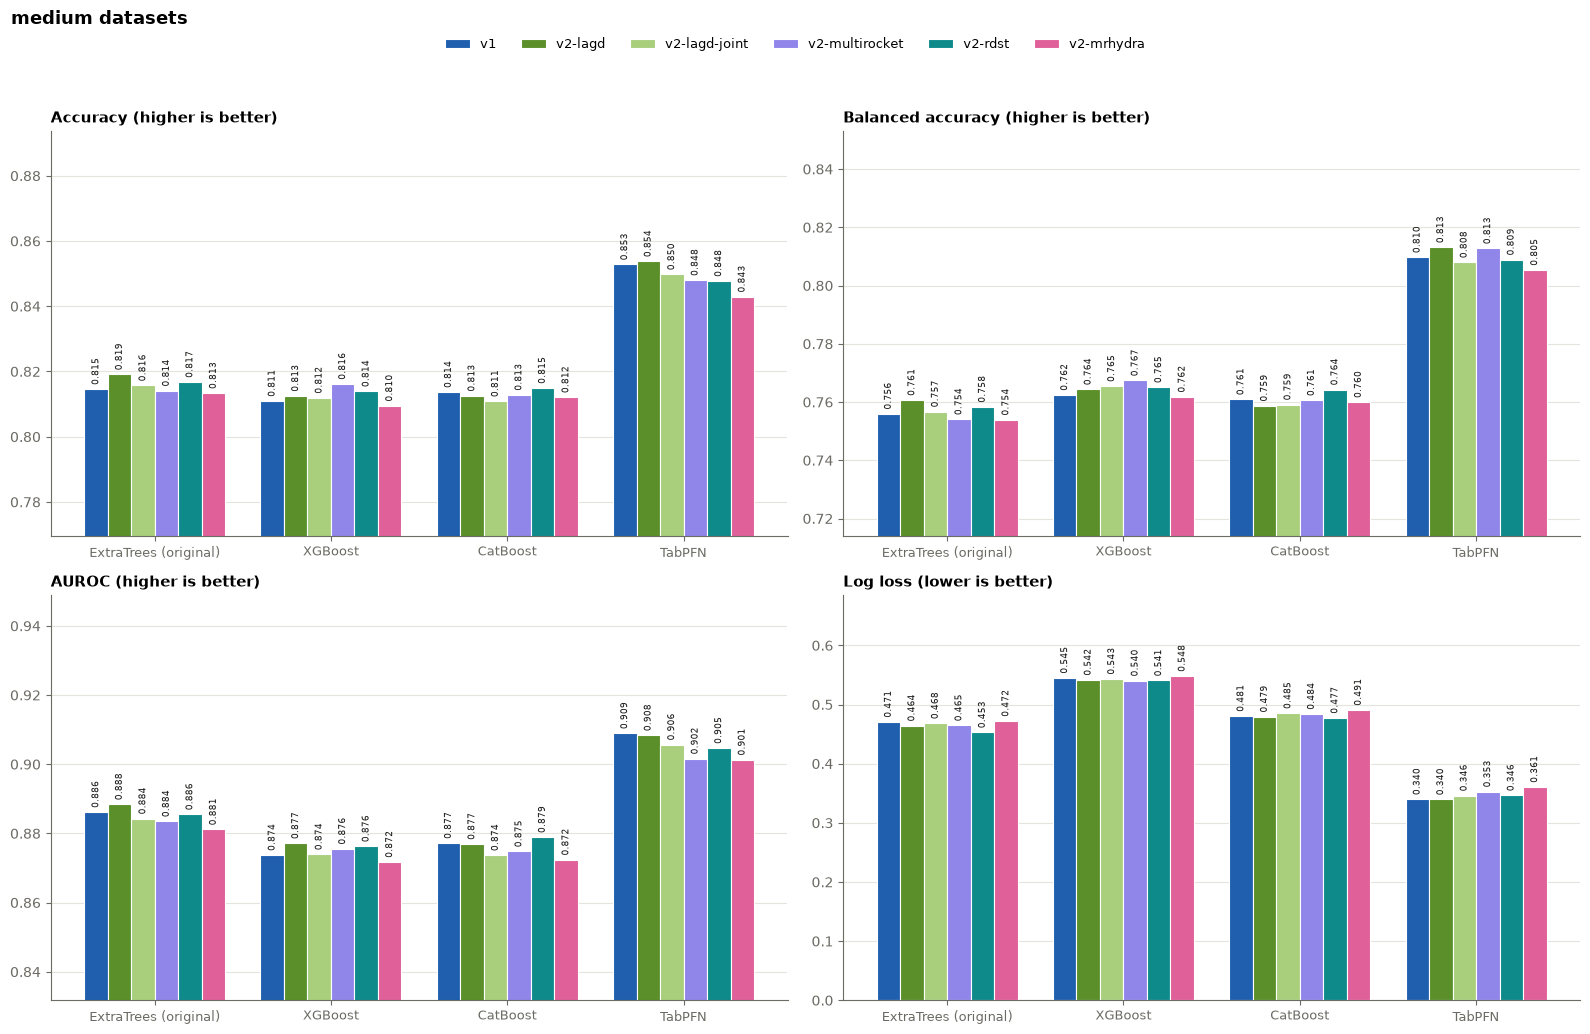

In [4]:
METRICS = ["accuracy", "balanced_accuracy", "auroc", "log_loss", "total_time"]
BAR_WIDTH = 0.8 / len(VERSIONS)        # all versions side by side in 80% of a classifier's width
SUMMARY = {}                           # per list: the mean of every metric per classifier and version (sections 7, 8)
panels = [("accuracy", "Accuracy (higher is better)"), ("balanced_accuracy", "Balanced accuracy (higher is better)"),
          ("auroc", "AUROC (higher is better)"), ("log_loss", "Log loss (lower is better)")]
for group in GROUPS:
    summary = RUNS[group].groupby(["classifier", "version"])[METRICS].mean()
    summary = SUMMARY[group] = summary.reindex(pd.MultiIndex.from_product([CLASSIFIERS, VERSIONS]))   # a fixed order
    fig, axes = plt.subplots(2, 2, figsize=(16, 10.5))
    for ax, (metric, title) in zip(axes.flat, panels):
        x = np.arange(len(CLASSIFIERS))
        for offset, v in zip(offsets(len(VERSIONS), BAR_WIDTH), VERSIONS):
            bars = ax.bar(x + offset, [summary.loc[(clf, v), metric] for clf in CLASSIFIERS], BAR_WIDTH,
                          color=VERSION_COLORS[v], edgecolor="white", linewidth=0.8, label=v)
            ax.bar_label(bars, fmt="{:.3f}", padding=3, fontsize=6.5, color=TEXT, rotation=90)
        ax.set_xticks(x, [LABELS[c] for c in CLASSIFIERS], fontsize=9)
        values = summary[metric]
        if metric == "log_loss":                                       # log loss from 0; the others zoomed in
            ax.set_ylim(0, values.max() * 1.25)
        else:
            ax.set_ylim(values.min() - 0.04, min(1.0, values.max()) + 0.04)
        ax.set_title(title, loc="left")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 0.965), fontsize=9)
    group_title(fig, group, top=0.93)
    plt.show()

Note: the y-axes of accuracy, balanced accuracy and AUROC do not start at 0, to make the differences visible.

## 5. Accuracy change compared with v1, per dataset

Each version's accuracy minus v1's accuracy, same classifier and dataset (mean over the 3 resamples); the last column
is the mean over the datasets. Blue: better than v1, red: worse, grey: about the same.

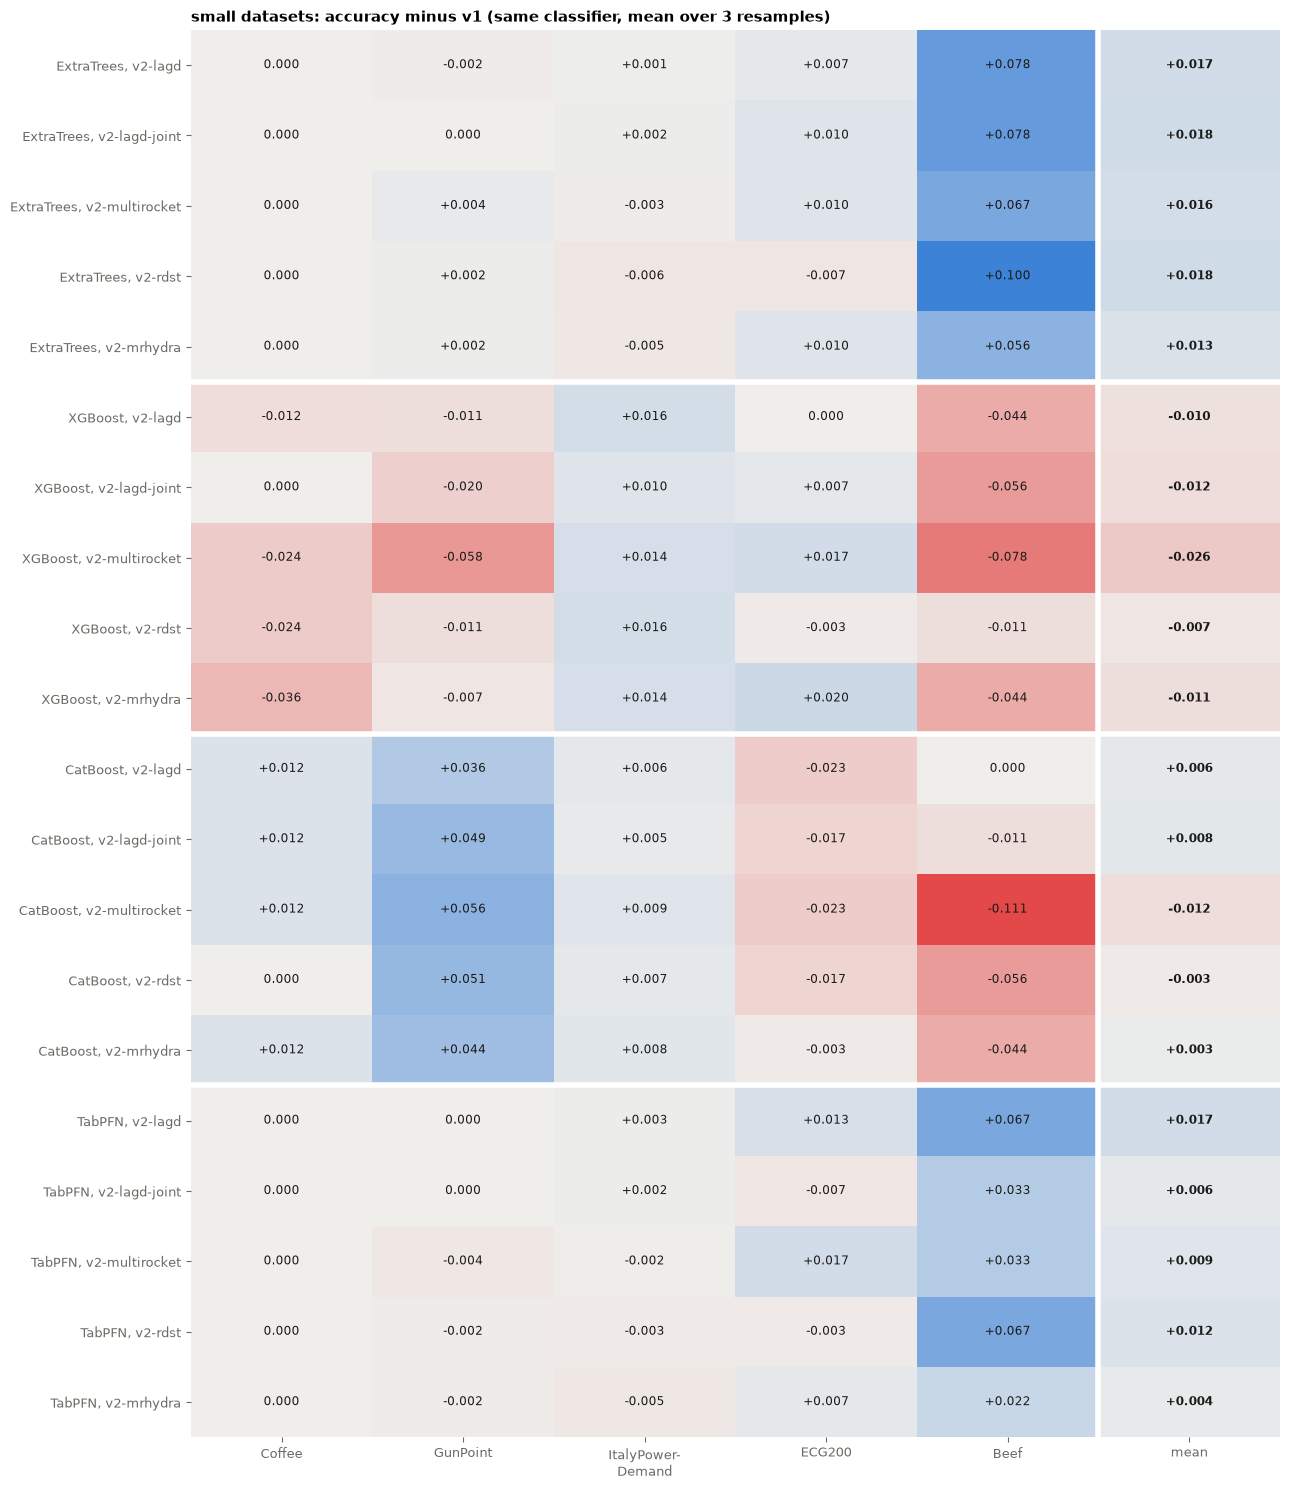

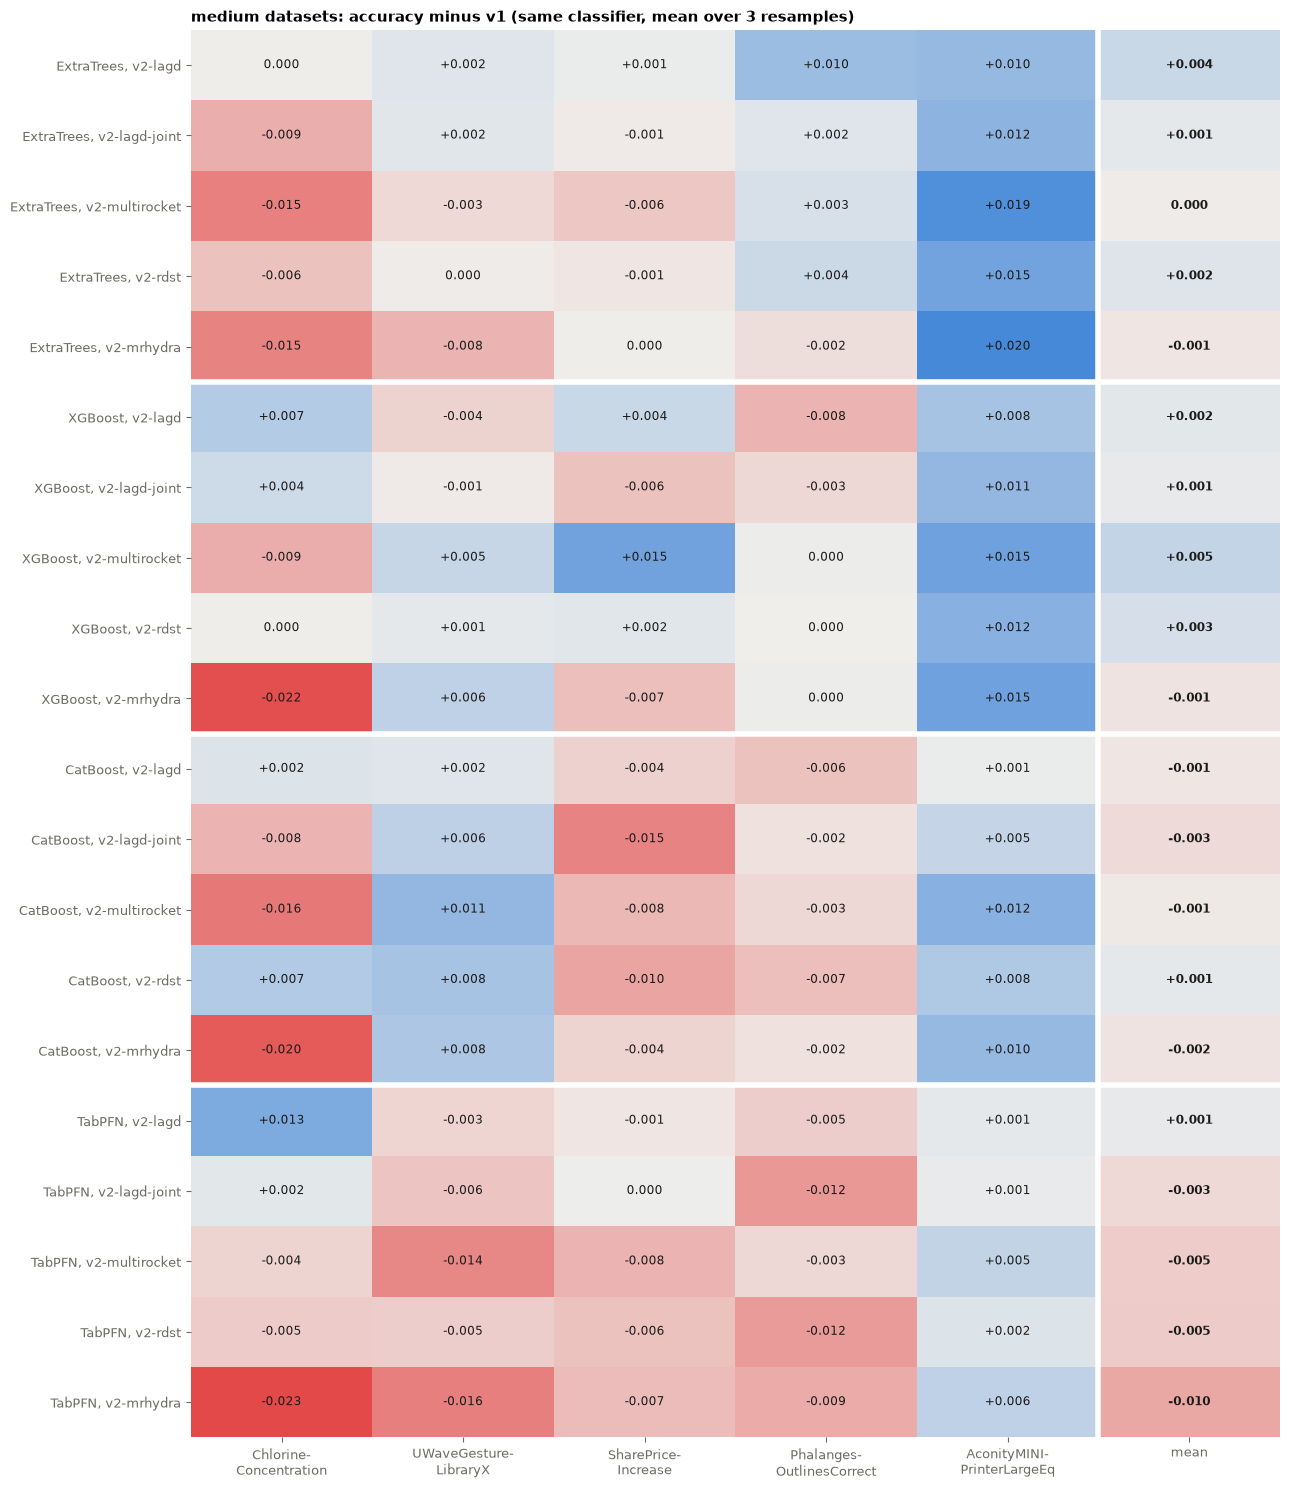

In [5]:
for group in GROUPS:
    names = DATASETS_OF[group]
    per_dataset = RUNS[group].groupby(["classifier", "version", "dataset"])["accuracy"].mean()   # mean of 3 resamples
    rows, labels = [], []
    for clf in CLASSIFIERS:
        for v in OTHERS:
            change = [per_dataset[(clf, v, name)] - per_dataset[(clf, "v1", name)] for name in names]
            rows.append(change + [np.mean(change)])                     # the last column: the mean over the datasets
            labels.append(f"{LABELS[clf].split(' (')[0]}, {v}")         # "ExtraTrees (original)" -> "ExtraTrees"
    values = np.array(rows)
    limit = max(0.01, np.abs(values).max())                             # the colour scale: -limit (red) to +limit (blue)

    fig, ax = plt.subplots(figsize=(13, 15))
    ax.imshow(values, cmap=DIVERGING, norm=TwoSlopeNorm(0, -limit, limit), aspect="auto")
    for r in range(values.shape[0]):
        for c in range(values.shape[1]):
            ax.text(c, r, signed(values[r, c]), ha="center", va="center", fontsize=8.5, color=TEXT,
                    fontweight="bold" if c == values.shape[1] - 1 else "normal")
    for r in range(len(OTHERS), values.shape[0], len(OTHERS)):          # white lines between the classifiers
        ax.axhline(r - 0.5, color="white", linewidth=4)
    ax.axvline(len(names) - 0.5, color="white", linewidth=4)            # and before the mean column
    ax.set_xticks(range(values.shape[1]), [short(d) for d in names] + ["mean"], fontsize=9)
    ax.set_yticks(range(values.shape[0]), labels, fontsize=9)
    ax.set_title(f"{group} datasets: accuracy minus v1 (same classifier, mean over 3 resamples)", loc="left")
    ax.grid(False)
    ax.spines[["left", "bottom"]].set_visible(False)
    fig.tight_layout()
    plt.show()

## 6. Where the time goes, for the original classifier (ExtraTrees)

Mean seconds per run over the 15 runs, split into the parts of the pipeline. The extra transform (MR-Hydra,
MultiRocket or RDST) is split into its training and test part; the test part of v2-multirocket and v2-rdst is small because
only the kept features are computed for the test set ("predict with few").

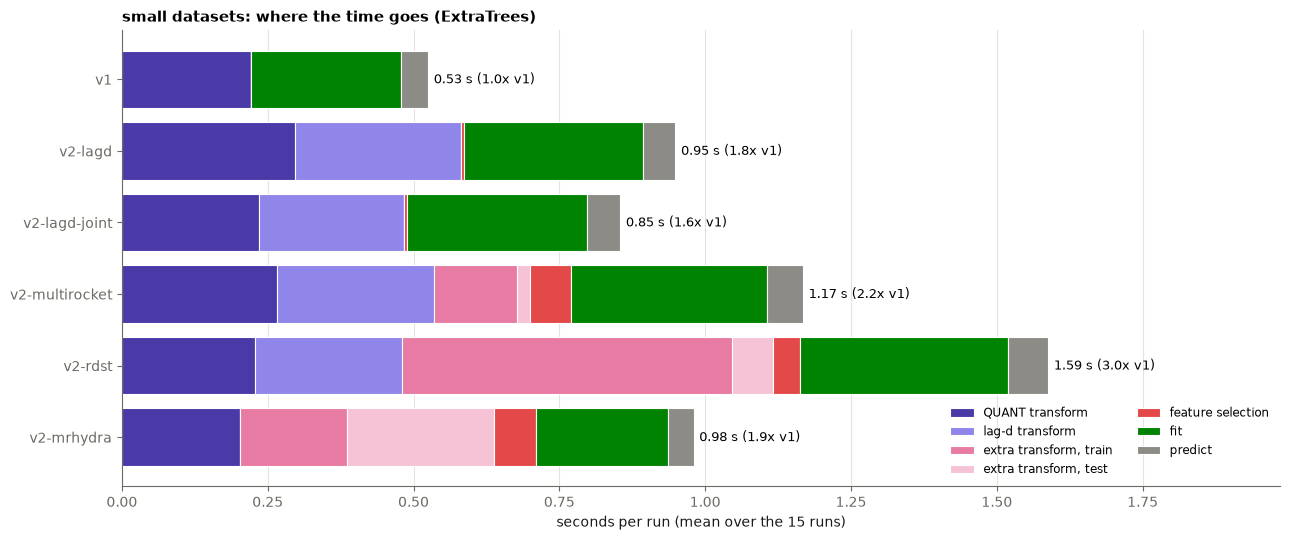

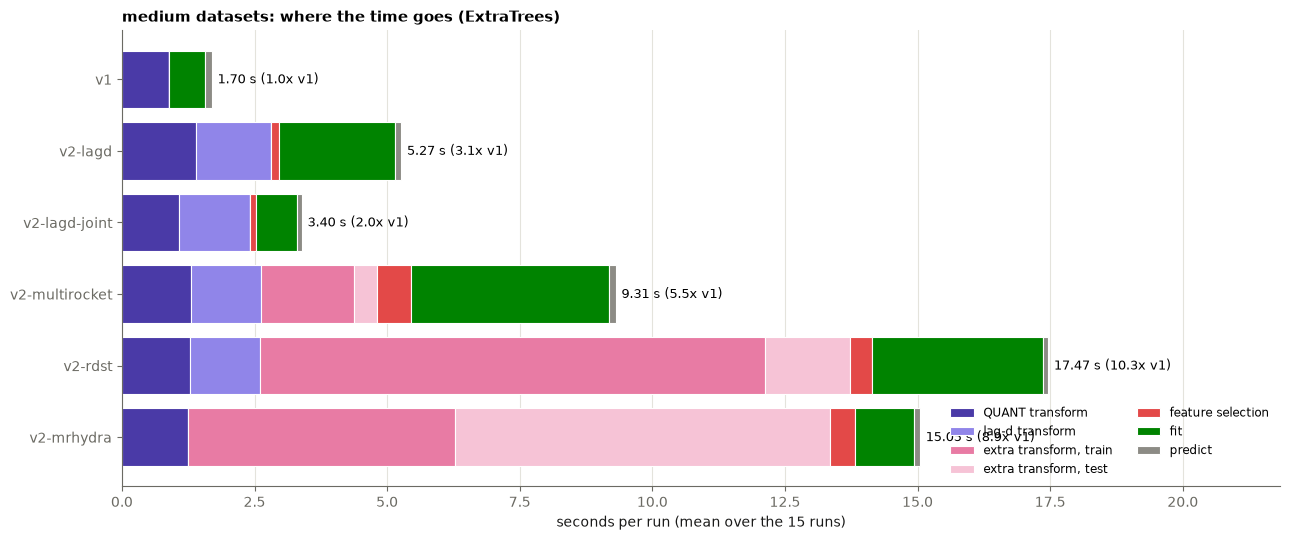

In [6]:
# the parts of the pipeline: the time columns added up for each part, and its colour
PARTS = {"QUANT transform": (["time_transform_train", "time_transform_test"], "#4a3aa7"),
         "lag-d transform": (["time_lag_train", "time_lag_test"], "#9085e9"),
         "extra transform, train": (["time_extra_train"], "#e87ba4"),
         "extra transform, test": (["time_extra_test"], "#f6c3d6"),
         "feature selection": (["time_select"], "#e34948"),
         "fit": (["time_fit"], "#008300"),
         "predict": (["time_predict"], "#8c8b85")}
for group in GROUPS:
    et = RUNS[group][RUNS[group]["classifier"] == "extratrees"]
    parts = pd.DataFrame({part: et[columns].sum(axis=1) for part, (columns, color) in PARTS.items()})
    breakdown = parts.groupby(et["version"]).mean().reindex(VERSIONS)  # the mean seconds per run of every version

    fig, ax = plt.subplots(figsize=(13, 5.5))
    y = np.arange(len(VERSIONS))[::-1]
    left = np.zeros(len(VERSIONS))
    for part, (columns, color) in PARTS.items():
        bars = ax.barh(y, breakdown[part], left=left, color=color, edgecolor="white", linewidth=0.8, label=part)
        left += breakdown[part].values
    ax.bar_label(bars, labels=[f"{total:.2f} s ({total / left[0]:.1f}x v1)" for total in left], padding=4, fontsize=9)
    ax.set_yticks(y, VERSIONS)
    ax.set_xlim(0, left.max() * 1.25)
    ax.set_xlabel("seconds per run (mean over the 15 runs)")
    ax.set_title(f"{group} datasets: where the time goes (ExtraTrees)", loc="left")
    ax.grid(True, axis="x")
    ax.grid(False, axis="y")
    ax.legend(loc="lower right", frameon=False, ncol=2, fontsize=8.5)
    fig.tight_layout()
    plt.show()

## 7. Accuracy vs time: the trade-off

One panel per classifier, one point per version (means over the runs). Up and to the left is better (more accurate,
faster). Time in seconds, linear axis; the labels are listed on the right, sorted by accuracy, with a line to each
point.

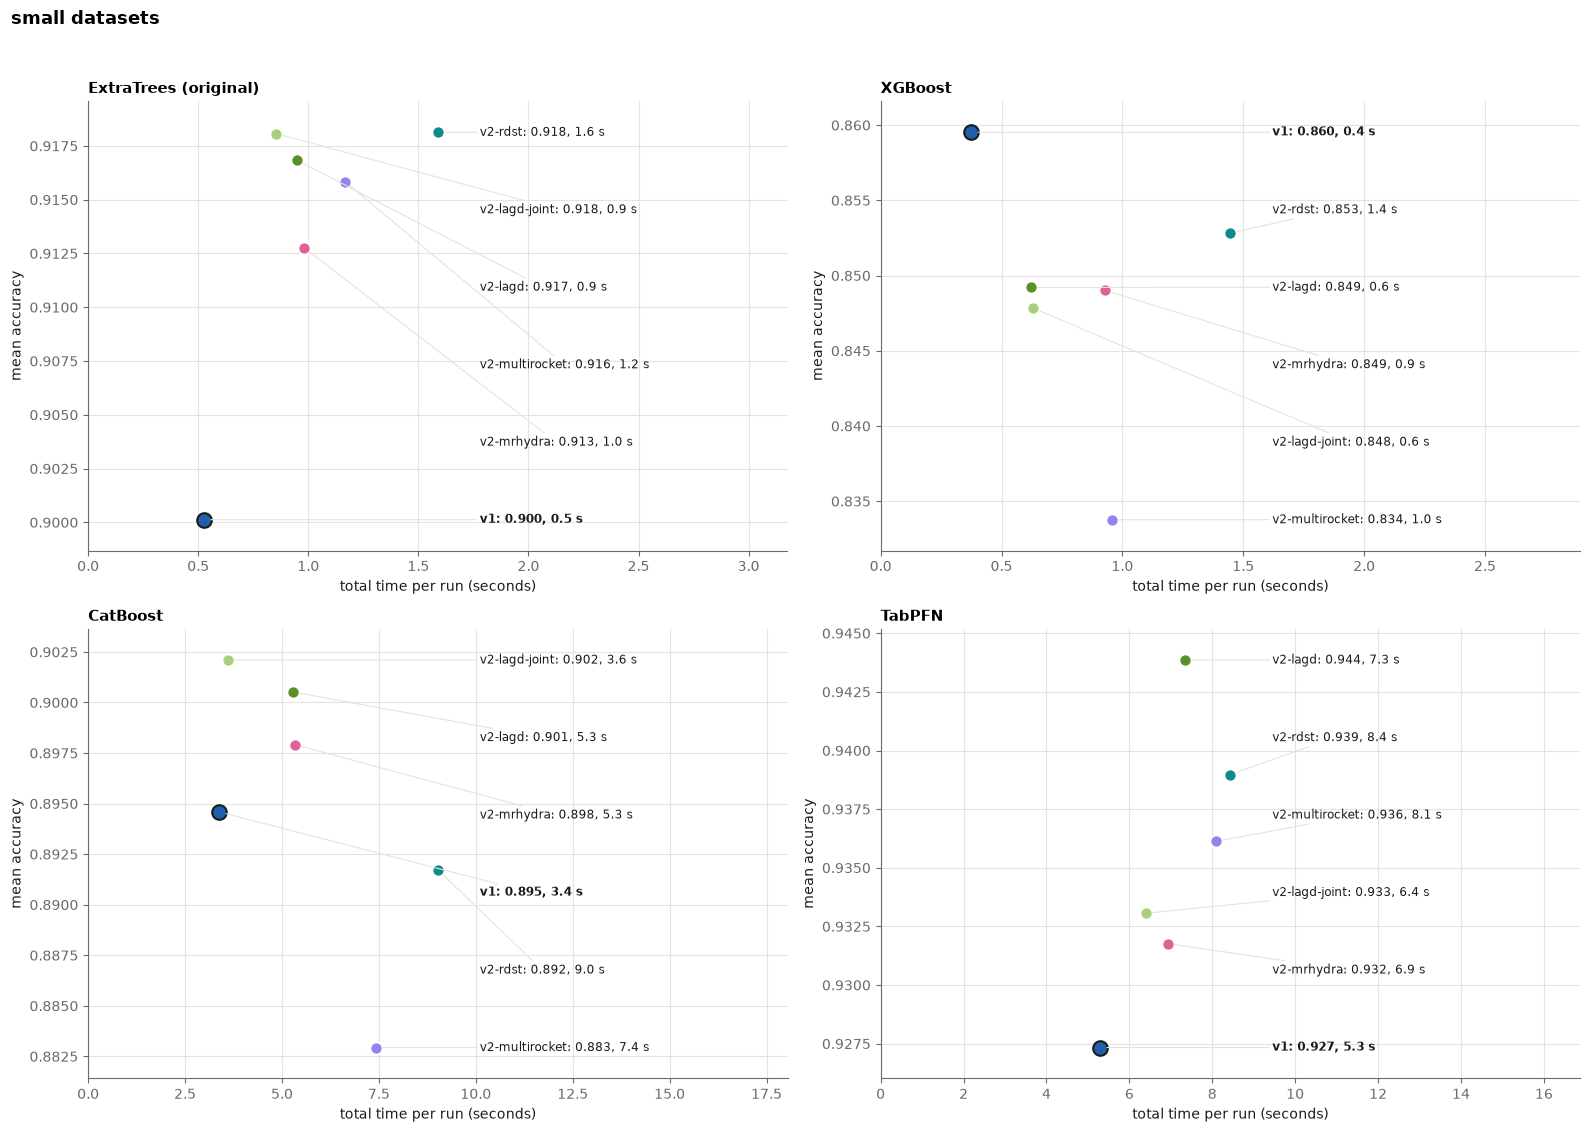

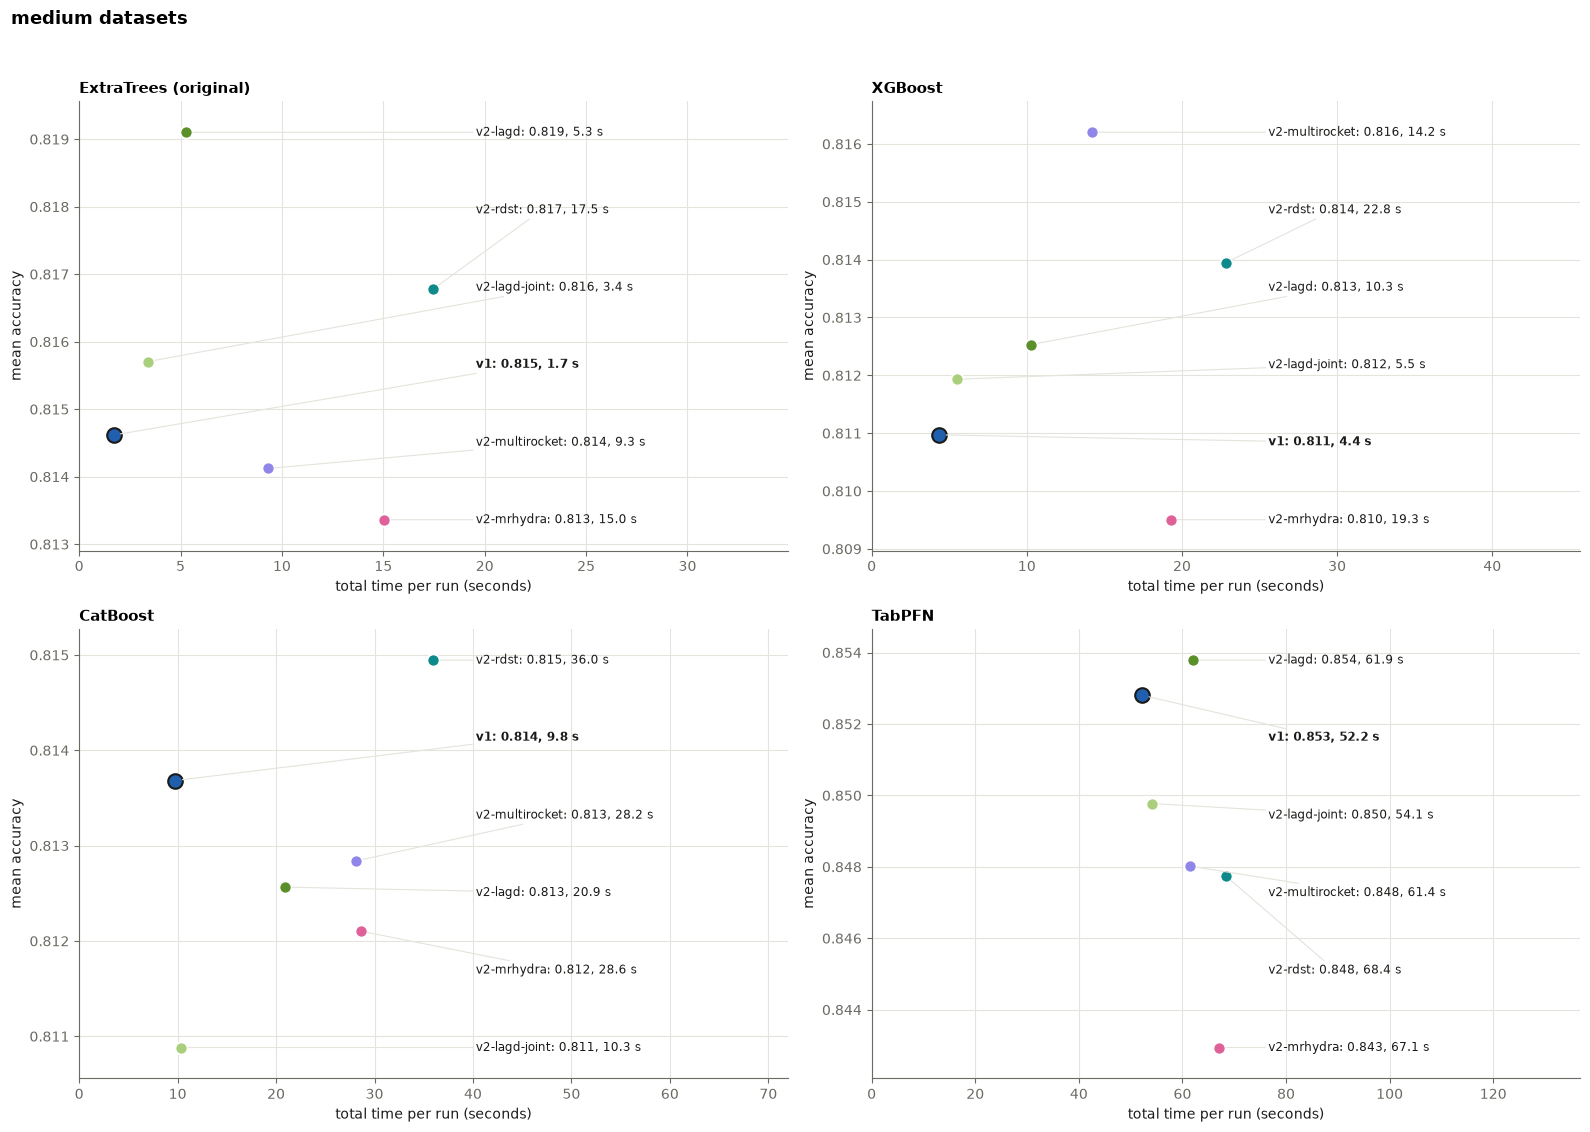

In [7]:
for group in GROUPS:
    summary = SUMMARY[group]
    fig, axes = plt.subplots(2, 2, figsize=(16, 11.5))
    for ax, clf in zip(axes.flat, CLASSIFIERS):
        s = summary.loc[clf]                                            # one row per version
        for v, row in s.iterrows():
            ax.scatter(row["total_time"], row["accuracy"], s=110 if v == "v1" else 80, color=VERSION_COLORS[v],
                       edgecolor=TEXT if v == "v1" else "white", linewidth=1.5, zorder=3)
        # the labels in a column on the right, sorted by accuracy, each with a thin line to its point
        x_right = s["total_time"].max()
        order = s.sort_values("accuracy", ascending=False)
        label_y = np.linspace(order["accuracy"].max(), order["accuracy"].min(), len(order))
        for (v, row), yy in zip(order.iterrows(), label_y):
            ax.annotate(f"{v}: {row['accuracy']:.3f}, {row['total_time']:.1f} s", (row["total_time"], row["accuracy"]),
                        xytext=(x_right * 1.12, yy), textcoords="data", va="center", fontsize=8.5, color=TEXT,
                        fontweight="bold" if v == "v1" else "normal",
                        arrowprops=dict(arrowstyle="-", color=GRID, linewidth=0.8, shrinkA=0, shrinkB=5))
        ax.set_xlim(0, x_right * 2.0)
        ax.margins(y=0.08)
        ax.set_xlabel("total time per run (seconds)")
        ax.set_ylabel("mean accuracy")
        ax.set_title(LABELS[clf], loc="left")
        ax.grid(True, axis="both")
    group_title(fig, group, top=0.96)
    plt.show()

## 8. Small vs medium datasets: does a gain hold?

The same versions on the small and on the medium datasets: the mean accuracy change against v1 per
classifier (15 runs each). Label: the change, and the total time
relative to v1.

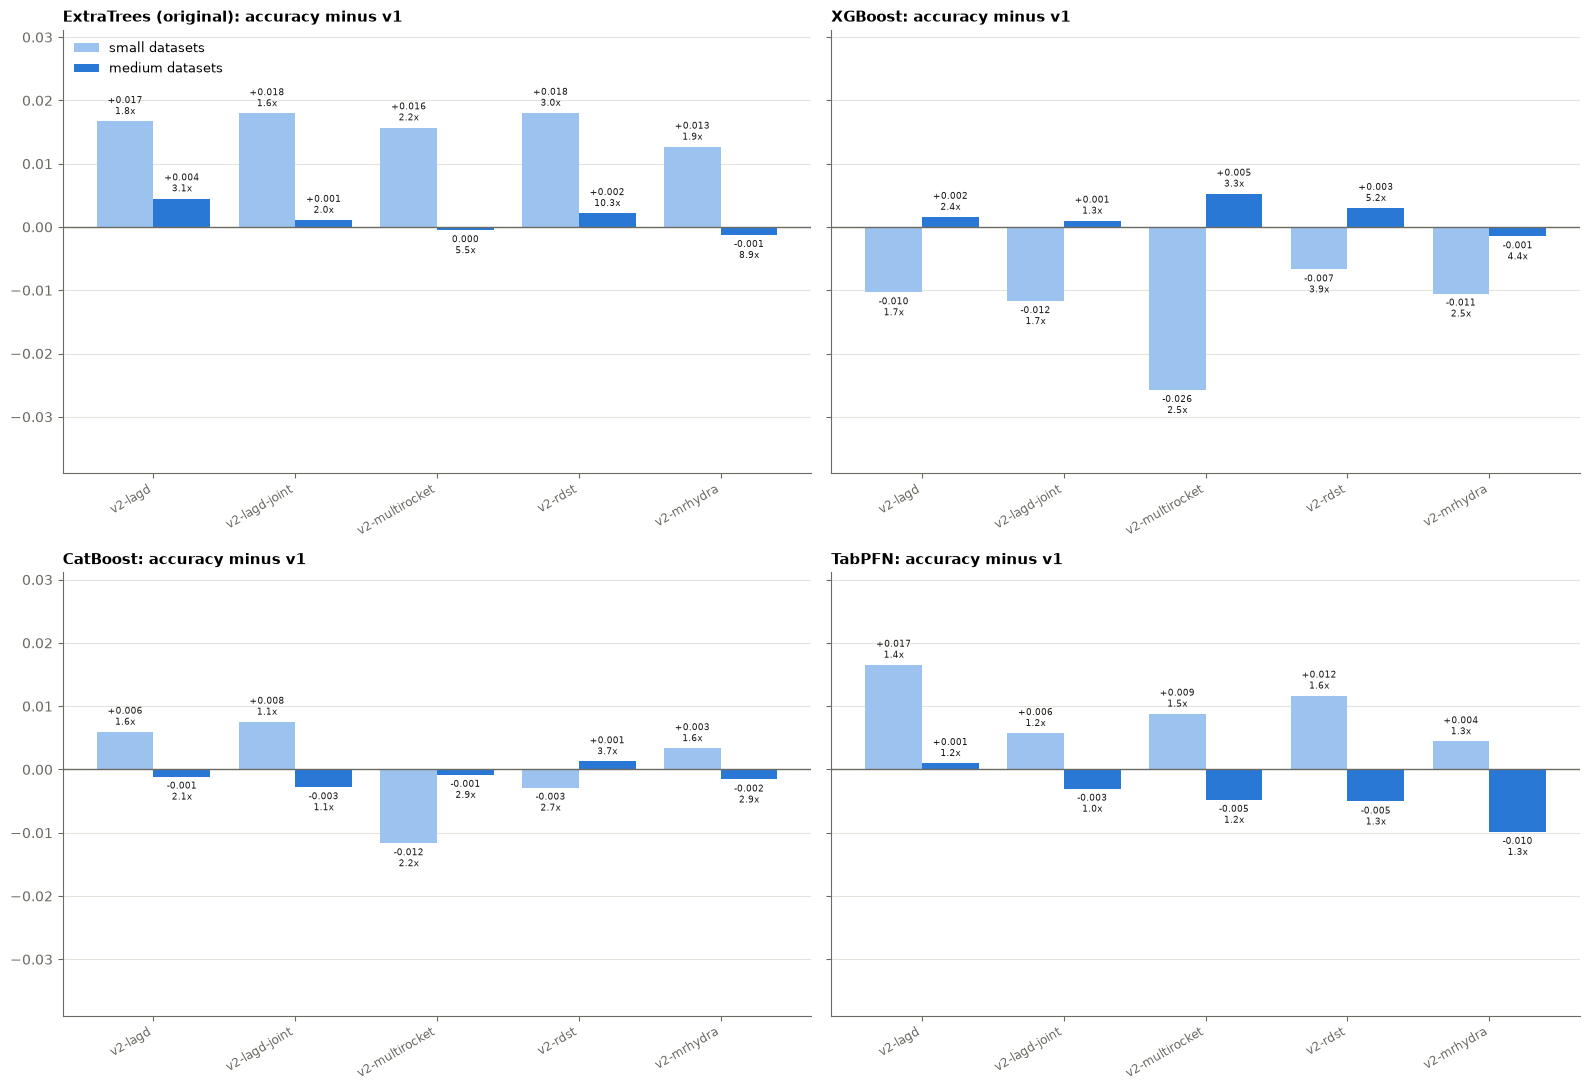

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11), sharey=True)
x = np.arange(len(OTHERS))
for ax, clf in zip(axes.flat, CLASSIFIERS):
    for offset, group, color in [(-0.2, "small", "#9cc3ef"), (0.2, "medium", "#2a78d6")]:
        s = SUMMARY[group].loc[clf]                                     # the means of every version (section 4)
        change = (s.loc[OTHERS, "accuracy"] - s.loc["v1", "accuracy"]).round(10)   # every version has v1's 15 runs
        time_ratio = s.loc[OTHERS, "total_time"] / s.loc["v1", "total_time"]
        ax.bar(x + offset, change, 0.4, color=color, label=f"{group} datasets")
        for xx, c, t in zip(x + offset, change, time_ratio):          # label: the change and the time relative to v1
            ax.annotate(f"{signed(c)}\n{t:.1f}x", (xx, c), xytext=(0, 3 if c >= 0 else -3), textcoords="offset points",
                        ha="center", va="bottom" if c >= 0 else "top", fontsize=6.5, color=TEXT)
    ax.axhline(0, color=MUTED, linewidth=1)
    ax.set_xticks(x, OTHERS, rotation=30, ha="right", fontsize=8.5)
    ax.set_title(f"{LABELS[clf]}: accuracy minus v1", loc="left")
    ax.margins(y=0.3)
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 9. Conclusions

- **No version clearly beats v1 on the medium datasets.** For ExtraTrees, XGBoost and CatBoost the mean change is
  between -0.003 and +0.005, for TabPFN between -0.010 and +0.001, smaller than the spread between resamples, and every
  version is slower: 2.0 to 10.3 times v1's time for ExtraTrees. The best one: ExtraTrees with v2-lagd (+0.004, better
  in 11 of 15 runs, 3.1x the time).
- **On the small datasets the extra features help ExtraTrees** (+0.013 to +0.018) **and TabPFN** (+0.004 to +0.017,
  v2-lagd the best), but not XGBoost (-0.007 to -0.026) or CatBoost (-0.012 to +0.008). With 28 to 100 training cases
  extra features help; with 467 to 2,403 the gain disappears (section 8).
- **Keeping all QUANT features is better than filtering them together with the new ones** (medium): v2-lagd vs
  v2-lagd-joint 0.819 vs 0.816 for ExtraTrees and 0.854 vs 0.850 for TabPFN.
- **MultiRocket, RDST and MR-Hydra add nothing beyond the lag-d differences:** on the medium datasets ExtraTrees gets
  0.814 (v2-multirocket), 0.817 (v2-rdst) and 0.813 (v2-mrhydra) against 0.819 for v2-lagd, at 5.5, 10.3 and 8.9
  times v1's time against 3.1; TabPFN loses with all three (-0.005 to -0.010).
- **Where the time goes (ExtraTrees, medium):** in v1 the QUANT transform (0.9 s) and the fit (0.7 s); in the
  extended versions the extra transform dominates (RDST 11 s, MR-Hydra 12 s, MultiRocket 2.2 s per run), even with
  only the kept features computed for the test set, and the larger feature sets also make the fit slower.
- **Overall:** a negative result beyond tiny training sets. The cheapest addition, the lag-d differences, is also the
  best one; it is kept for the next steps (v3 uses v2-lagd's features, v4 and later versions use lag-d views).

Caveat: smoke tests (5 datasets x 3 resamples per list), no significance tests.